# Budowa i analiza modeli
Niniejszy notatnik ma na celu wyłonienie modelu uczenia maszynowego, który najskuteczniej klasyfikuje pacjentów pod kątem występowania zaburzeń poznawczych. Cechy, na których oparte zostaną modele, znajdują się w pliku features_reduced.csv i zostały wyznaczone na podstawie sygnałów z badania polisomnograficznego. Macierz cech jest wciąż przewymiarowana - zawiera 172 cechy przy 412 obserwacjach uczących - dlatego jej redukcja nastąpi na etapie budowy modeli, poprzez regularyzację i wbudowaną selekcję cech. Zbiór jest zrównoważony (po 50% obserwacji w każdej klasie), dzięki czemu przyjęte miary zachowują się stabilnie.
W notatniku zbudowane zostaną trzy modele:

- regresja logistyczna,
- gradient boosting,
- las losowy.

Ocena modeli opiera się na dwóch grupach miar. Pierwsza wynika z macierzy pomyłek liczonej dla ustalonego progu decyzyjnego: czułość, precyzja oraz F1. Druga to pole pod krzywą ROC (AUC), które jest niezależne od progu, ponieważ agreguje skuteczność klasyfikatora po wszystkich możliwych progach.

## 1. Regresja logistyczna
Regresja logistyczna modeluje prawdopodobieństwo przynależności do klasy. Jej zaletą jest interpretowalność - współczynniki przekładają się na logarytmy szans, a po przekształceniu na ilorazy szans, więc wprost można ocenić siłę poszczególnych cech. Model zwraca prawdopodbieństwo a nie etykietę, dlatego ostateczną klasyfikację dokonuję poprzez przyłożene progu. Przesuwanie progu pozwala świadomie sterować kompromisem między czułością a precyzją: obniżenie progu zwiększa czułość kosztem precyzji, a podniesienie progu działa odwrotnie, co daje elastyczność w dostrojeniu. Model będzie regularyzowany przy pomocy regularyzacji l1, w celu zmniejszenia wymiarowości. Regresja logistyczna nie przyjmuje cech wybrakowanych, dlatego wszelkie braki zostaną zastąpione medianą.
### 1.1 Budowa modelu


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, recall_score, precision_score, f1_score)

DATA_PATH = "/home/emil/studia/inzynierka/data/gold/features_reduced.csv"
SPLIT_PATH = "/home/emil/studia/inzynierka/references/split.json"

df = pd.read_csv(DATA_PATH)
with open(SPLIT_PATH) as f:
    split = json.load(f)

target = "Cognitive_Impairment"
meta = ["BidsFolder", "SiteID", target]

df["N3_present"] = (df["N3_time"] > 0).astype(int)
df["REM_present"] = (df["REM_time"] > 0).astype(int)

features = [c for c in df.columns if c not in meta]
categorical_features = ["Sex"]
numeric_features = [c for c in features if c not in categorical_features]

def get_subset(ids):
    data = df[df["BidsFolder"].isin(ids)]
    return data[features], data[target].astype(int)

X_train, y_train = get_subset(split["splits"]["train"])
X_val, y_val = get_subset(split["splits"]["val"])
X_test, y_test = get_subset(split["splits"]["test"])

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

In [2]:
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", OneHotEncoder(drop="if_binary"), categorical_features),
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(penalty="l1", solver="saga",
                                 max_iter=5000, random_state=42)),
])

cv_strategy = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
param_grid = {
    "model__C": np.logspace(-2, 1, 7),
}

grid_search = GridSearchCV(pipeline, param_grid, scoring="roc_auc", cv=cv_strategy, n_jobs=-1)
grid_search.fit(X_trval, y_trval)
best_pipeline = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("AUC (cross-validation):", round(grid_search.best_score_, 3))
print("Number of non-zero features:",
      int(np.sum(best_pipeline.named_steps["model"].coef_ != 0)))

/home/emil/.local/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/emil/.local/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/emil/.local/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/emil/.local/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/emil/.local/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/emil/.local/lib/python3.10/site-packages/sklearn/linear_model/_sag.py:348: Convergen

Best parameters: {'model__C': np.float64(0.03162277660168379)}
AUC (cross-validation): 0.653
Number of non-zero features: 1


In [3]:
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
coefficients = best_pipeline.named_steps["model"].coef_.ravel()
selected_features = pd.Series(coefficients, index=feature_names)
selected_features = selected_features[selected_features != 0].sort_values(key=np.abs, ascending=False)

print("Features selected by the model:")
print(selected_features.round(4))

Features selected by the model:
num__kurtosis_frontal_N2   -0.2719
dtype: float64


In [4]:
threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(best_pipeline, X_trval, y_trval,
                              cv=threshold_cv, method="predict_proba")[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_trval, oof_probs)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("Decision threshold (max F1):", round(best_threshold, 3))

Decision threshold (max F1): 0.467


In [5]:
threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(best_pipeline, X_trval, y_trval,
                              cv=threshold_cv, method="predict_proba")[:, 1]
fpr, tpr, roc_thresholds = roc_curve(y_trval, oof_probs)
best_threshold = roc_thresholds[np.argmax(tpr - fpr)]

print("Decision threshold (max sensitivity + specificity):", round(best_threshold, 3))

Decision threshold (max sensitivity + specificity): 0.503


Model zbudowano w potoku obejmującym przygotowanie cech i klasyfikator. Cecha kategoryczna Sex została zakodowana binarnie. Siłę regularyzacji dobrano poprzez walidację krzyżową na połączonym zbiorze uczącym i walidacyjnym, optymalizując pole pod krzywą ROC. Wybrana została silna kara (C = 0,03), co spowodowało wyzerowanie wag wszystkich cech oprócz jednej. Jest to odbicie wykazanej już wcześniej słabej zależności liniowej - pole pod krzywą zmienia się znikomo niezależnie od tego, czy model wykorzystuje jedną, czy kilkanaście cech. Próg decyzyjny dobrano na podstawie predykcji z walidacji krzyżowej, jako wartość maksymalizującą miarę F1. Otrzymana wartość (około 0,47) leży nieco poniżej 0,5, co lekko faworyzuje czułość kosztem precyzji.

### 1.2 Testowanie modelu

AUC: 0.676
Recall: 0.881
Precision: 0.536
F1: 0.667
Confusion matrix:
 [[10 32]
 [ 5 37]]


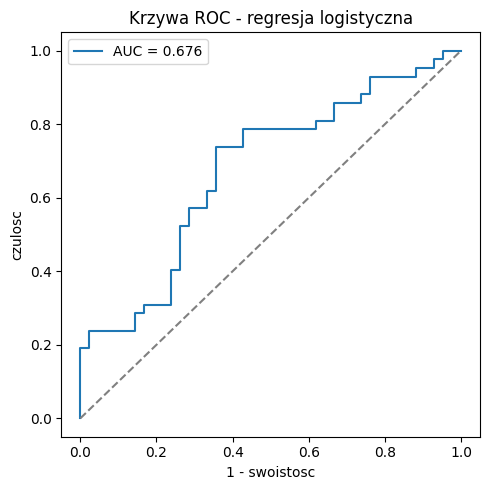

In [6]:
test_probs = best_pipeline.predict_proba(X_test)[:, 1]
y_pred = (test_probs >= 0.467).astype(int)

print("AUC:", round(roc_auc_score(y_test, test_probs), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("F1:", round(f1_score(y_test, y_pred), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, test_probs):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - swoistosc")
plt.ylabel("czulosc")
plt.title("Krzywa ROC - regresja logistyczna")
plt.legend()
plt.tight_layout()
plt.show()

AUC: 0.676
Czulosc: 0.738
Precyzja: 0.633
F1: 0.681
Macierz pomylek:
 [[24 18]
 [11 31]]


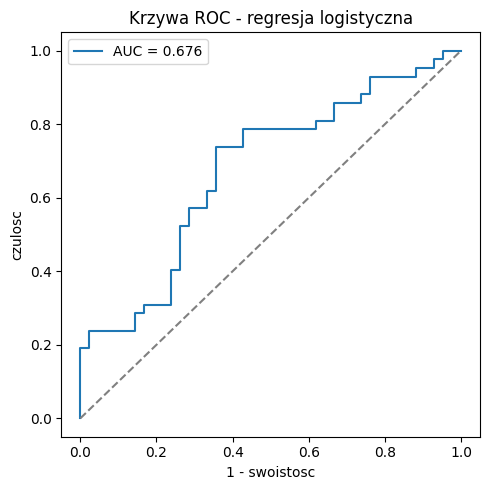

In [7]:
test_probs = best_pipeline.predict_proba(X_test)[:, 1]
y_pred = (test_probs >= 0.503).astype(int)

print("AUC:", round(roc_auc_score(y_test, test_probs), 3))
print("Czulosc:", round(recall_score(y_test, y_pred), 3))
print("Precyzja:", round(precision_score(y_test, y_pred), 3))
print("F1:", round(f1_score(y_test, y_pred), 3))
print("Macierz pomylek:\n", confusion_matrix(y_test, y_pred))

fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, test_probs):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - swoistosc")
plt.ylabel("czulosc")
plt.title("Krzywa ROC - regresja logistyczna")
plt.legend()
plt.tight_layout()
plt.show()

Model regresji logistycznej osiągnął AUC na poziomie 0,676. Przy progu maksymalizującym sumę czułości i swoistości model uzyskał zrównoważony punkt pracy - czułość 0,738 i precyzję 0,633 przy F1 równym 0,681. Przy progu maksymalizującym F1 czułość osiągnęła znaczną przewagę nad precyzją - 0,881 do 0,536 - co jest pożądane dla danych biologicznych, mało pacjentów z faktycznym schorzeniem zostaje pominiętych. Mimo wszystko model jako klasyfikator jest dość słaby i nie gwarantuje poprawnych wyników.

### 1.3 Wnioski
Model regresji logistycznej ostatecznie potwierdził brak liniowych zależności między cechami opisującymi a zmienną opisywaną. Ostatcznie najlepszy okazał się być model zawierający tylko jedną cechę - kurtosis_frontal_N2, która na etapie analizy eksploracyjnej okazała się być zmienną najlepiej skorelowaną z targetem. Ujemna wartość współćżynnika wskazuje na zależność odwrotnie proporcjonalną do cechy opisywanej - im niższa kurtoza tym większe prawdopodbieństwo zaburzeń poznawczych. Zwiększenie liczby cech nie zawiększyło jakości modelu, więc te cechy nie niosły dodatkowego sygnału. Mimo wszystko model regresji logistycznej okazał się być dość słaby, osiągając na zbiorze testowym AUC równe 0,676. Dzięki swojej wysokiej czułości model jest dobrze zbalansowany pod dniagnostykę - pacjenci chorzy są rzadko pomijani, jednakże dzieje się to kosztem precyzji. Model oceniono przy dwóch progach decyzyjnych - maksymalizującym sumę czułości i swoistości oraz maksymalizującym F1; pierwszy daje bardziej zrównoważony punkt pracy (czułość 0,738, precyzja 0,633), drugi wyraźnie wyższą czułość kosztem precyzji, co pozwala świadomie dobrać kompromis między pomijaniem chorych a liczbą fałszywych alarmów. Ograniczenia wynikające z liniowości regresji logistycznej potwierdzają konieczność zastosowania modelu nieliniowego

## 2. Gradient boosting
Gradient boosting buduje klasyfikator jako sumę wielu płytkich drzew decyzyjnych dodawanych sekwencyjnie - każde kolejne drzewo koryguje błędy poprzednika. Dzięki temu model wychwytuje nieliniowe zależności i interakcje między cechami, których regresja logistyczna nie była w stanie uchwycić. Drzewa są niewrażliwe na skalę cech, więc standaryzacja jest zbędna. Zamiast zastępować braki medianą, jak w regresji logistycznej, pozwalamy modelowi traktować brak jako osobną informację. Cechy są redukowane przy pomocy:  głębokości drzew, tempa uczenia, regularyzacji l2 oraz minimalną liczbą obserwacji w liściu. Model zwraca prawdopodobieństwo, a próg decyzyjny dobierany jest tak samo jak w przypadku regresji logistycznej - przez maksymalizację F1 na predykcjach z walidacji krzyżowej.
### 2.1 Budowa modelu

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

preprocessing_gb = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("kat", OneHotEncoder(drop="if_binary"), categorical_features),
])

gb = Pipeline([
    ("przetwarzanie", preprocessing_gb),
    ("model", HistGradientBoostingClassifier(early_stopping=False, random_state=42)),
])

grid_gb = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_leaf_nodes": [7, 15, 31],
    "model__min_samples_leaf": [20, 40],
    "model__l2_regularization": [0.0, 1.0],
    "model__max_iter": [200],
}

search_gb = GridSearchCV(gb, grid_gb, scoring="roc_auc", cv=cv_strategy, n_jobs=-1)
search_gb.fit(X_trval, y_trval)
best_gb = search_gb.best_estimator_

print("Najlepsze parametry:", search_gb.best_params_)
print("AUC (walidacja krzyzowa):", round(search_gb.best_score_, 3))

Najlepsze parametry: {'model__l2_regularization': 0.0, 'model__learning_rate': 0.03, 'model__max_iter': 200, 'model__max_leaf_nodes': 7, 'model__min_samples_leaf': 20}
AUC (walidacja krzyzowa): 0.61


In [9]:
perm_imp = permutation_importance(best_gb, X_trval, y_trval,
                                  scoring="roc_auc", n_repeats=10,
                                  random_state=42, n_jobs=-1)
feature_names_gb = best_gb.named_steps["przetwarzanie"].get_feature_names_out()
importances = pd.Series(perm_imp.importances_mean, index=feature_names_gb)
importances = importances[importances > 0].sort_values(ascending=False)
print("Liczba cech o dodatnim wplywie:", int((perm_imp.importances_mean > 0).sum()))
print("Najwazniejsze cechy (waznosc permutacyjna):")
print(importances.head(15).round(4))

Liczba cech o dodatnim wplywie: 89
Najwazniejsze cechy (waznosc permutacyjna):
num__delta_kurtosis_frontal_N2       0.0066
num__line_length_frontal_N2          0.0041
num__TRT                             0.0011
num__sigma_kurtosis_frontal_W        0.0009
num__alpha_kurtosis_occipital_N3     0.0007
num__sigma_rel_power_frontal_N3      0.0007
num__kurtosis_frontal_REM            0.0006
num__alpha_kurtosis_frontal_N3       0.0006
num__theta_kurtosis_occipital_N2     0.0004
num__theta_rel_power_frontal_N1      0.0003
num__sigma_rel_power_frontal_N2      0.0002
num__delta_kurtosis_occipital_REM    0.0002
num__sigma_rel_power_occipital_N2    0.0001
num__sigma_kurtosis_occipital_N3     0.0001
num__sigma_rel_power_frontal_N1      0.0001
dtype: float64


In [10]:
oof_probs_gb = cross_val_predict(best_gb, X_trval, y_trval,
                                 cv=threshold_cv, method="predict_proba")[:, 1]
fpr_gb, tpr_gb, roc_thresholds_gb = roc_curve(y_trval, oof_probs_gb)
best_threshold_gb = roc_thresholds_gb[np.argmax(tpr_gb - fpr_gb)]

print("Próg decyzyjny:", round(best_threshold_gb, 3))

Próg decyzyjny: 0.54


In [11]:
oof_gb = cross_val_predict(best_gb, X_trval, y_trval,
                           cv=threshold_cv, method="predict_proba")[:, 1]
prec_gb, rec_gb, thresholds_gb = precision_recall_curve(y_trval, oof_gb)
f1_gb = 2 * prec_gb * rec_gb / (prec_gb + rec_gb + 1e-9)
threshold_gb = thresholds_gb[np.argmax(f1_gb[:-1])]
print("Próg decyzyjny (maks. F1):", round(threshold_gb, 3))

Próg decyzyjny (maks. F1): 0.154


Model zbudowano w analogicznym potoku co regresję, z trzema różnicami wynikającymi z natury drzew: pominięto standaryzację (drzewa są na nią niewrażliwe) oraz imputację (HistGradientBoosting dzieli węzły na brakujących wartościach natywnie, zachowując informację o nieobecności fazy snu), a cechę Sex nadal zakodowano binarnie. Hiperparametry - tempo uczenia, rozmiar drzew, regularyzację l2 i minimalną liczność liścia - dobrano tą samą walidacją krzyżową na połączonym zbiorze uczącym i walidacyjnym, optymalizując pole pod krzywą ROC. Progi zostały dobrane na dwa sposoby: na podstawie predykcji z walidacji krzyżowej, jako wartość maksymalizująca sumę czułości i swoistości - czyli punkt na krzywej ROC najlepiej rozdzielający klasy oraz maksymalizację F1 - tak jak w regresji logistycznej.
### 2.2 Testowanie modelu

AUC: 0.704
Czulosc: 0.69
Precyzja: 0.644
F1: 0.667
Macierz pomylek:
 [[26 16]
 [13 29]]


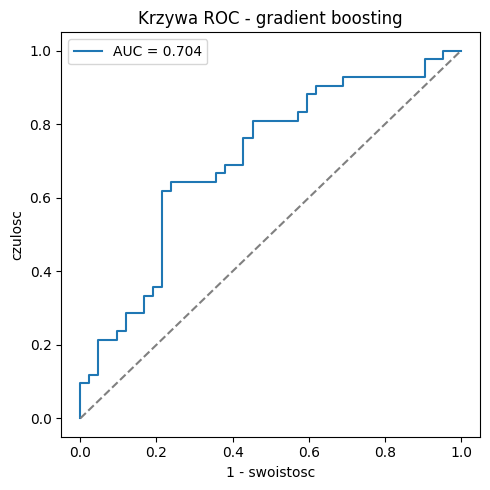

In [12]:
p_test_gb = best_gb.predict_proba(X_test)[:, 1]
y_pred_gb = (p_test_gb >= 0.54).astype(int)

print("AUC:", round(roc_auc_score(y_test, p_test_gb), 3))
print("Czulosc:", round(recall_score(y_test, y_pred_gb), 3))
print("Precyzja:", round(precision_score(y_test, y_pred_gb), 3))
print("F1:", round(f1_score(y_test, y_pred_gb), 3))
print("Macierz pomylek:\n", confusion_matrix(y_test, y_pred_gb))

fpr, tpr, _ = roc_curve(y_test, p_test_gb)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, p_test_gb):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - swoistosc")
plt.ylabel("czulosc")
plt.title("Krzywa ROC - gradient boosting")
plt.legend()
plt.tight_layout()
plt.show()

AUC: 0.704
Czulosc: 0.976
Precyzja: 0.512
F1: 0.672
Macierz pomylek:
 [[ 3 39]
 [ 1 41]]


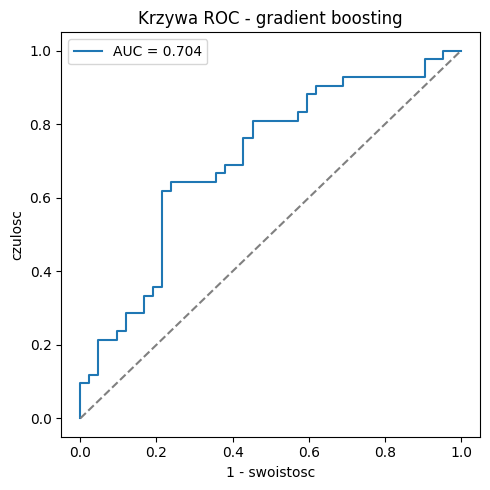

In [13]:
p_test_gb = best_gb.predict_proba(X_test)[:, 1]
y_pred_gb = (p_test_gb >= 0.154).astype(int)

print("AUC:", round(roc_auc_score(y_test, p_test_gb), 3))
print("Czulosc:", round(recall_score(y_test, y_pred_gb), 3))
print("Precyzja:", round(precision_score(y_test, y_pred_gb), 3))
print("F1:", round(f1_score(y_test, y_pred_gb), 3))
print("Macierz pomylek:\n", confusion_matrix(y_test, y_pred_gb))

fpr, tpr, _ = roc_curve(y_test, p_test_gb)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, p_test_gb):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - swoistosc")
plt.ylabel("czulosc")
plt.title("Krzywa ROC - gradient boosting")
plt.legend()
plt.tight_layout()
plt.show()

Model został przetestowany na dwóch progach - maksymalizującym sumę czułości i swoistości (0,54) oraz maksymalizującym F1 (0,154). Przy tym samym AUC (0,704) pierwszy daje zrównoważoną macierz pomyłek, a drugi spycha klasyfikację niemal wyłącznie ku predykcjom pozytywnym, co potwierdza, że wiarygodną miarą jakości pozostaje AUC.

### 2.3 Wnioski
Nieliniowy model gradient boosting osiągnął trochę, choć nieznacznie, lepsze AUC niż model regresji logistycznej. Porównanie doboru progów pokazuje ich zupełnie inne zachowanie przy tym samym AUC: próg maksymalizujący sumę czułości i swoistości (0,54) daje zrównoważony punkt pracy, podczas gdy próg maksymalizujący F1 (0,154) sprowadza klasyfikację niemal wyłącznie do predykcji pozytywnych, osiągając bardzo wysoką czułość, przy praktycznie identycznej wartości F1 (0,672 wobec 0,667). Potwierdza to, że dla tego modelu kryterium F1 wyznacza próg niewłaściwie, a sensowny punkt pracy daje dopiero równoważenie czułości i swoistości. Najbardziej wiarygodną miarą miarą jakości pozostaje AUC. Najbardziej istotnymi cechami dla modelu również były cechy wyprowadzone z sygnałów eeg, jednak inne niż w przypadku regresji logistycznej. Potwierdza to wartość tych cech w przewidywaniu występowania zaburzeń poznawczych.

## 3. Las losowy
Las losowy uśrednia predykcje wielu drzew decyzyjnych budowanych na losowych podpróbkach obserwacji i cech (bagging). W odróżnieniu od gradient boostingu jest on bardziej odporny na przetrenowanie i szum. Podobnie jak w gradient boostingu, drzewa są niewrażliwe na skalę, więc standaryzacja jest zbędna, jednak implementacja lasu losowego nie obsługuje braków, dlatego są onezastępowane medianą, jak w regresji logistycznej, a informację o nieobecności fazy snu zachowują dodane cechy binarne. Las nie ma wbudowanej  regularyzacji, więc nadmiarowość kontroluje się ograniczeniem głębokości drzew, minimalną licznością liścia oraz liczbą cech rozważanych przy każdym podziale.
### 3.1 Budowa modelu

In [14]:
from sklearn.ensemble import RandomForestClassifier

preprocessing_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("kat", OneHotEncoder(drop="if_binary"), categorical_features),
])

rf = Pipeline([
    ("przetwarzanie", preprocessing_rf),
    ("model", RandomForestClassifier(n_estimators=400, random_state=42, n_jobs=-1)),
])

grid_rf = {
    "model__max_depth": [3, 4, 6],
    "model__min_samples_leaf": [10, 20, 40],
    "model__max_features": ["sqrt", 0.2],
}

search_rf = GridSearchCV(rf, grid_rf, scoring="roc_auc", cv=cv_strategy, n_jobs=-1)
search_rf.fit(X_trval, y_trval)
best_rf = search_rf.best_estimator_

print("Najlepsze parametry:", search_rf.best_params_)
print("AUC (walidacja krzyzowa):", round(search_rf.best_score_, 3))

Najlepsze parametry: {'model__max_depth': 4, 'model__max_features': 0.2, 'model__min_samples_leaf': 10}
AUC (walidacja krzyzowa): 0.642


In [15]:
perm_imp_rf = permutation_importance(best_rf, X_trval, y_trval,
                                     scoring="roc_auc", n_repeats=10,
                                     random_state=42, n_jobs=-1)
feature_names_rf = best_rf.named_steps["przetwarzanie"].get_feature_names_out()
importances_rf = pd.Series(perm_imp_rf.importances_mean, index=feature_names_rf)
importances_rf = importances_rf[importances_rf > 0].sort_values(ascending=False)
print("Liczba cech o dodatnim wplywie:", int((perm_imp_rf.importances_mean > 0).sum()))
print("Najwazniejsze cechy (waznosc permutacyjna):")
print(importances_rf.head(15).round(4))

Liczba cech o dodatnim wplywie: 168
Najwazniejsze cechy (waznosc permutacyjna):
num__sigma_rel_power_frontal_N2      0.0106
num__theta_kurtosis_occipital_N2     0.0081
num__line_length_frontal_N2          0.0079
num__delta_kurtosis_frontal_N2       0.0064
num__kurtosis_frontal_REM            0.0053
num__sigma_kurtosis_occipital_N3     0.0041
num__alpha_kurtosis_occipital_REM    0.0028
num__TRT                             0.0026
num__theta_rel_power_frontal_N1      0.0025
num__hjorth_activity_occipital_N2    0.0023
num__alpha_kurtosis_frontal_N3       0.0023
num__delta_kurtosis_occipital_REM    0.0022
num__delta_kurtosis_frontal_W        0.0021
num__hjorth_complexity_central_N1    0.0020
num__sigma_rel_power_frontal_N3      0.0019
dtype: float64


In [16]:
oof_rf = cross_val_predict(best_rf, X_trval, y_trval,
                           cv=threshold_cv, method="predict_proba")[:, 1]
prec_rf, rec_rf, thresholds_rf = precision_recall_curve(y_trval, oof_rf)
f1_rf = 2 * prec_rf * rec_rf / (prec_rf + rec_rf + 1e-9)
threshold_rf = thresholds_rf[np.argmax(f1_rf[:-1])]
print("Próg decyzyjny (maks. F1):", round(threshold_rf, 3))

Próg decyzyjny (maks. F1): 0.354


In [17]:
oof_rf = cross_val_predict(best_rf, X_trval, y_trval,
                           cv=threshold_cv, method="predict_proba")[:, 1]
fpr_rf, tpr_rf, roc_thresholds_rf = roc_curve(y_trval, oof_rf)
threshold_rf = roc_thresholds_rf[np.argmax(tpr_rf - fpr_rf)]
print("Próg decyzyjny (maks. czulosc + swoistosc):", round(threshold_rf, 3))

Próg decyzyjny (maks. czulosc + swoistosc): 0.485


Model zbudowano w analogicznym potoku co poprzednie, z imputacją medianą wymuszoną brakiem natywnej obsługi wartości brakujących w lesie losowym; standaryzację pominięto, ponieważ drzewa są na nią niewrażliwe, a cechę Sex zakodowano binarnie. Hiperparametry - głębokość drzew, minimalną liczność liścia oraz liczbę cech rozważanych przy podziale - dobrano tą samą walidacją krzyżową na połączonym zbiorze uczącym i walidacyjnym, optymalizując pole pod krzywą ROC.
### 3.2 Testowanie modelu

AUC: 0.726
Czulosc: 1.0
Precyzja: 0.519
F1: 0.683
Macierz pomylek:
 [[ 3 39]
 [ 0 42]]


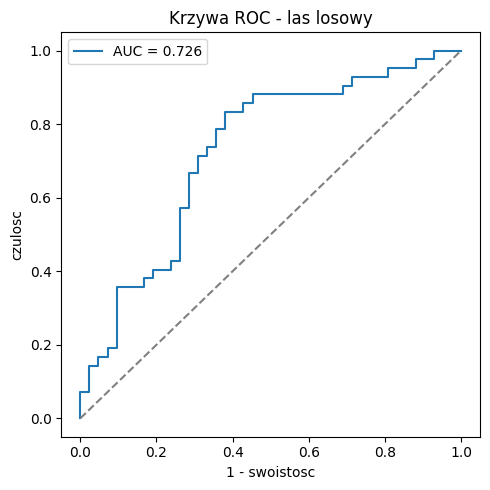

In [18]:
p_test_rf = best_rf.predict_proba(X_test)[:, 1]
y_pred_rf = (p_test_rf >= 0.354).astype(int)

print("AUC:", round(roc_auc_score(y_test, p_test_rf), 3))
print("Czulosc:", round(recall_score(y_test, y_pred_rf), 3))
print("Precyzja:", round(precision_score(y_test, y_pred_rf), 3))
print("F1:", round(f1_score(y_test, y_pred_rf), 3))
print("Macierz pomylek:\n", confusion_matrix(y_test, y_pred_rf))

fpr, tpr, _ = roc_curve(y_test, p_test_rf)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, p_test_rf):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - swoistosc")
plt.ylabel("czulosc")
plt.title("Krzywa ROC - las losowy")
plt.legend()
plt.tight_layout()
plt.show()

AUC: 0.726
Czulosc: 0.857
Precyzja: 0.667
F1: 0.75
Macierz pomylek:
 [[24 18]
 [ 6 36]]


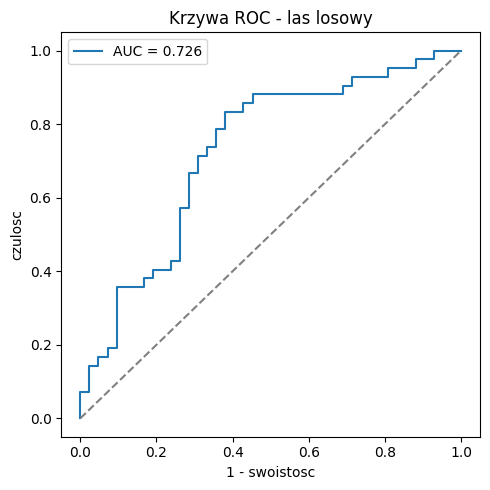

In [19]:
p_test_rf = best_rf.predict_proba(X_test)[:, 1]
y_pred_rf = (p_test_rf >= 0.485).astype(int)

print("AUC:", round(roc_auc_score(y_test, p_test_rf), 3))
print("Czulosc:", round(recall_score(y_test, y_pred_rf), 3))
print("Precyzja:", round(precision_score(y_test, y_pred_rf), 3))
print("F1:", round(f1_score(y_test, y_pred_rf), 3))
print("Macierz pomylek:\n", confusion_matrix(y_test, y_pred_rf))

fpr, tpr, _ = roc_curve(y_test, p_test_rf)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, p_test_rf):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - swoistosc")
plt.ylabel("czulosc")
plt.title("Krzywa ROC - las losowy")
plt.legend()
plt.tight_layout()
plt.show()

Las losowy osiągnął AUC na poziomie 0,726 - najwyższe na zbiorze testowym spośród trzech modeli. Przy progu maksymalizującym sumę czułości i swoistości (0,485) uzyskał najbardziej zrównoważzone rezultay - czułość 0,857, precyzję 0,667 i F1 równe 0,75. Próg maksymalizujący F1 (0,354) ponownie zdegenerował klasyfikację niemal wyłącznie do predykcji pozytywnych (czułość 1,0, precyzja 0,519) przy niższym F1 (0,683). Potwierdza to obserwację z gradient boostingu, że dla modeli drzewiastych sensowny próg daje dopiero równoważenie czułości i swoistości, a wiarygodną miarą jakości pozostaje progowo-niezależne AUC.
### 3.3 Wnioski
Las losowy okazał się być najskuteczniejszym z analizowanych modeli. Najwyżej oceniane pozostały cechy ze stadium N2 - moc względna sigma oraz kurtoza - zgodnie z wcześniejszymi modelami i analizą eksploracyjną, co utrwala wniosek, że to cechy wyekstrahowane z kanałów eeg niosą najwięcej sygnału predykcyjnego. Przewaga lasu nad gradient boostingiem wynika z uśredniania niezależnych drzew, tłumiącego wariancję wnoszoną przez nadmiarowe cechy.

## 4. Podsumowanie
### Jakość modeli
Spośród trzech modeli najlepiej poradził sobie las losowy, osiągając na zbiorze testowym AUC 0,726 wobec 0,704 dla gradient boostingu i 0,676 dla regresji logistycznej. Przy progu równoważącym czułość i swoistość las uzyskał najbardziej zrównoważone wartości cech jakościowych - czułość 0,857, precyzję 0,667 i F1 0,75. Osiągnął on wynik lepszy niż Gradiend Boosting za sprawą baggingu - uśrednienie wielu niezależnych drzew zredukowało wariancję wnoszoną przez nadmiarowe cechy, przez co model był odporniejszy na szum i przetrenowanie. Za najbardziej wiarygodną miarę jakości przyjęto AUC, ponieważ jest niezależne od progu; dobór progu przez maksymalizację F1 okazał się dla modeli drzewiastych zawodny i sprowadzał klasyfikację niemal wyłącznie do predykcji pozytywnych, maksymalizując czułość.
### Istotne cechy
Wszystkie modele uznawały cechy z sygnałów eeg za najistotniejsze, więc zdecydowanie to one niosły najwięcej sygnały predykcyjnego. Regularyzacja L1 w regresji logistycznej zredukowała ilość cech do jednej: kurtosis_frontal_N2, z ujemnym współczynnikiem (im niższa kurtoza, tym wyższe prawdopodobieństwo zaburzeń). Modele nieliniowe wskazywały szerszy zestaw cech zdominowany przez cechy oparte o kurtozę i mocy względną pasm w fazie N2. W gradient boostingu czołowe były delta_kurtosis_frontal_N2 oraz line_length_frontal_N2, a w lesie losowym sigma_rel_power_frontal_N2, theta_kurtosis_occipital_N2 i line_length_frontal_N2. 
### Możliwości rozwoju
Kierunkiem dalszych prac jest budowa modelu głębokiego uczenia, który nie będzie uczył się z wyekstrahowanych cech, lecz na całych sygnałach, gdzie możliwie lepiej będzie znajdował zależności czasowe i wielowymiarowe. W celu poprawienia istniejących już modeli uczenia maszynowego, ekstrakcja cech musiałaby zostać poszerzona o atrybuty, których obecny zestaw nie obejmuje - miary łączności między kanałami EEG, zmienność rytmu serca (HRV) wyliczoną z EKG oraz cechy z sygnałów oddechowych, a dodatkowo o cechy pochodne i interakcje między istniejącymi atrybutami. Dałoby to modelom liniowym i drzewiastym dostęp do informacji, której pojedyncze, agregowane na pacjenta cechy w obecnej postaci nie zawierają.